In [1]:
import requests
import json

weather_url = "https://api.open-meteo.com/v1/forecast"
weather_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "temperature_2m,relative_humidity_2m",
    "timezone": "Asia/Karachi",
}

r = requests.get(weather_url, params=weather_params)
print("Status:", r.status_code)

data = r.json()
print(data.keys())
print(json.dumps(data, indent=2)[:1500])


Status: 200
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
{
  "latitude": 31.528997,
  "longitude": 74.38995,
  "generationtime_ms": 0.22995471954345703,
  "utc_offset_seconds": 18000,
  "timezone": "Asia/Karachi",
  "timezone_abbreviation": "GMT+5",
  "elevation": 222.0,
  "hourly_units": {
    "time": "iso8601",
    "temperature_2m": "\u00b0C",
    "relative_humidity_2m": "%"
  },
  "hourly": {
    "time": [
      "2026-11-01T00:00",
      "2026-11-01T01:00",
      "2026-11-01T02:00",
      "2026-11-01T03:00",
      "2026-11-01T04:00",
      "2026-11-01T05:00",
      "2026-11-01T06:00",
      "2026-11-01T07:00",
      "2026-11-01T08:00",
      "2026-11-01T09:00",
      "2026-11-01T10:00",
      "2026-11-01T11:00",
      "2026-11-01T12:00",
      "2026-11-01T13:00",
      "2026-11-01T14:00",
      "2026-11-01T15:00",
      "2026-11-01T16:00",
      "2026-11-01T17:00",
      "2

In [7]:
import pandas as pd

aq_url = "https://air-quality-api.open-meteo.com/v1/air-quality"
aq_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "timezone": "Asia/Karachi",
}

r = requests.get(aq_url, params=aq_params)
print("Status:", r.status_code)

aq = r.json()
aq_df = pd.DataFrame(aq["hourly"])
aq_df["time"] = pd.to_datetime(aq_df["time"])
print(aq_df.head())
print(aq_df.shape)

Status: 200
                 time   pm10  pm2_5  us_aqi
0 2026-11-01 00:00:00  120.1  113.6   168.0
1 2026-11-01 01:00:00  121.1  114.3   169.0
2 2026-11-01 02:00:00  120.6  113.9   169.0
3 2026-11-01 03:00:00  118.5  111.8   170.0
4 2026-11-01 04:00:00  117.8  111.3   170.0
(120, 4)


In [2]:
print(data["hourly"].keys())
print(data["hourly"]["time"][0])
print(data["hourly"]["temperature_2m"][0])


dict_keys(['time', 'temperature_2m', 'relative_humidity_2m'])
2026-11-01T00:00
20.2


In [3]:

print(data["hourly"]["time"][1])
print(data["hourly"]["temperature_2m"][1])
print(len(data["hourly"]["time"]))


2026-11-01T01:00
19.7
168


In [4]:
import pandas as pd

df = pd.DataFrame(data["hourly"])
print(df.head())
print(df.shape)


               time  temperature_2m  relative_humidity_2m
0  2026-11-01T00:00            20.2                    78
1  2026-11-01T01:00            19.7                    78
2  2026-11-01T02:00            19.1                    81
3  2026-11-01T03:00            18.6                    83
4  2026-11-01T04:00            18.4                    83
(168, 3)


In [5]:
df["time"] = pd.to_datetime(df["time"])
print(df.dtypes)
print(df["temperature_2m"].max(), df["temperature_2m"].min())

time                    datetime64[ns]
temperature_2m                 float64
relative_humidity_2m             int64
dtype: object
28.7 17.4


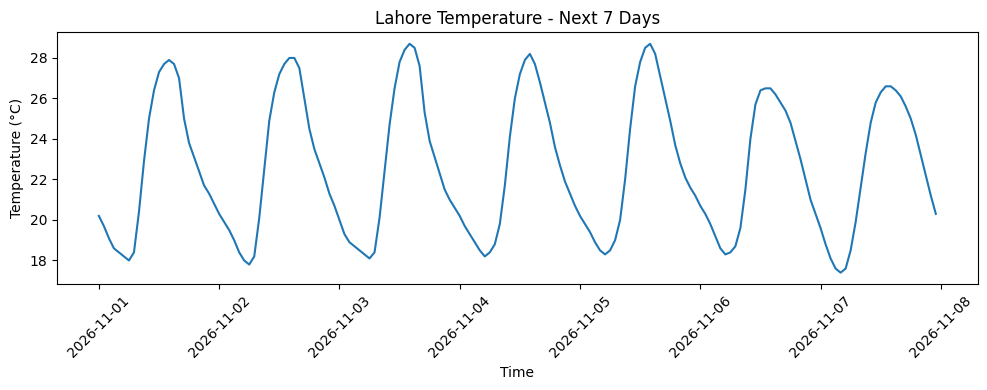

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["temperature_2m"])
plt.title("Lahore Temperature - Next 7 Days")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

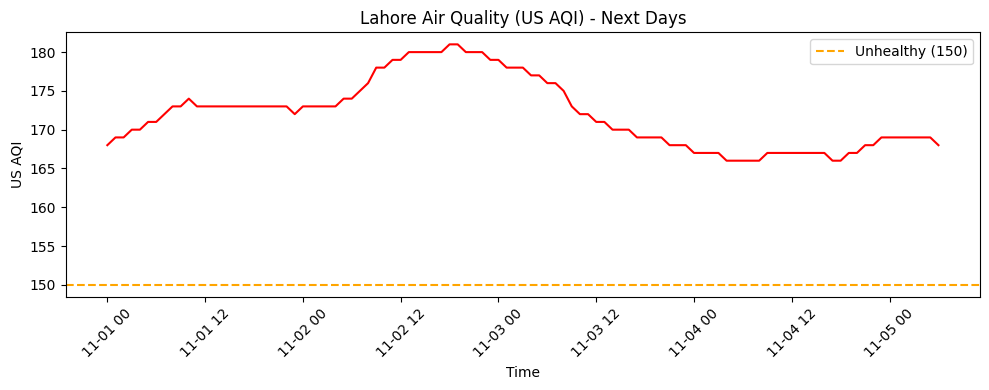

Max AQI: 181.0
Average AQI: 172.0097087378641


In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(aq_df["time"], aq_df["us_aqi"], color="red")
plt.axhline(150, color="orange", linestyle="--", label="Unhealthy (150)")
plt.title("Lahore Air Quality (US AQI) - Next Days")
plt.xlabel("Time")
plt.ylabel("US AQI")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print("Max AQI:", aq_df["us_aqi"].max())
print("Average AQI:", aq_df["us_aqi"].mean())